# Caso práctico -  Análisis de las transacciones de un negocio ecommerce
### 📈 <b>Contexto del negocio y la situación:</b>

Imagina que eres un analista de datos trabjando para una empresa ecommerce minorista que vende una variedad de productos online, que van desde equipos electrónicos y ropa hasta artículos para el hogar y accesorios. Tu tarea es analizar las transacciones de los clientes desde 2023 para identificar tendencias, comprender el comportamiento del cliente y optimizar la gestión de inventario.

### 📍 <b>Objetivos:</b>

- Comprender el comportamiento del cliente: Analizar la frecuencia de las compras, el valor promedio de las compras y los productos más populares.
- Optimizar el inventario: Identificar productos con altas tasas de devolución para ajustar los niveles de inventario.
- Mejorar las ventas y el marketing: Identificar segmentos de clientes que puedan ser objetivos de campañas de marketing para aumentar las ventas.
- Opcional: utilizar algún modelo de ML para hacer segmentación de clientes, predicción de ventas, de Customer Churn u otras propuestas.

### 💾 Descripción de los datos
- TransactionID: Identificador único para cada transacción.
- CustomerID: Identificador único para cada cliente.
- TransactionDate: Fecha y hora de la transacción.
- ProductID: Identificador único para cada producto.
- ProductCategory: Categoría del producto (por ejemplo, Electrónica, Ropa, Artículos para el hogar).
- Quantity: Número de unidades compradas.
- Price: Precio por unidad del producto.
- PaymentMethod: Método de pago (por ejemplo, Tarjeta de crédito, PayPal, Transferencia bancaria).
- ReturnStatus: Indica si el artículo fue devuelto (Sí o No).
- CustomerFeedback: Rating del 1 al 10 que representa la valoración del cliente.
- DiscountApplied: Porcentaje de descuento que se ha aplicado sobre el producto.
- ShippingCost: Coste del envío en euros.

Esta plantilla te guiará a través del proceso de análisis inicial y pre-procesado de los datos, pero es solo una guía! Puedes añadir o quitar lo que creas conveniente o analizar otros aspectos que te parezcan interesantes. Recuerda que hay muchas formas de llegar al mismo resultado, y lo que más se valora es la proactividad! 😃

In [7]:
# Importar las librerías necesarias
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
# Cargar los datos (ecommerce_data.csv)
df = pd.read_csv(r"C:\Users\Adrian\Desktop\CODE_SPACE\Ejercicios\Python_Basics_for_DS\data\ecommerce\ecommerce_data.csv")



***

# 1. Exploración Inicial
El primer paso de cualquier análisis es realizar una exploración inicial de los datos. Entender qué tipo de información lleva cada columna, las unidades, los tipos de variables y tener una idea general de errores a gestionar en los siguientes pasos.

In [9]:
# Utiliza los métodos que conozcas para explorar el dataset
# ¿Cuántas filas y columnas tiene?
display(df.head())
display(df.shape)

,TransactionID,CustomerID,TransactionDate,ProductID,ProductCategory,Quantity,Price,PaymentMethod,ReturnStatus,CustomerFeedback,DiscountApplied,ShippingCost
0,TXN100000,CUST1012,2023-06-05 11:11:00,PROD215,books,NaN,238.10,Credit Card,Yes,4.344676,15.04,47.16
1,TXN100001,CUST1125,2023-03-13 13:16:59,PROD300,Home Goods,10,480.70,Bank Transfer,Yes,6.534869,13.70,30.15
2,TXN100002,CUST1377,2023-11-17 19:39:50,PROD230,Electronics,3,361.89,Credit Card,No,8.076073,19.09,15.58
3,TXN100003,CUST1379,2023-01-03 14:41:06,PROD283,Books,two,9.69,NaN,Yes,4.855980,31.34,35.70
4,TXN100004,CUST1044,2023-05-21 21:42:03,PROD214,Home Goods,NaN,351.01,Credit Card,No,2.042956,39.82,4.04


(5050, 12)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   TransactionID     5050 non-null   object 
 1   CustomerID        4802 non-null   object 
 2   TransactionDate   5050 non-null   object 
 3   ProductID         4959 non-null   object 
 4   ProductCategory   5050 non-null   object 
 5   Quantity          4432 non-null   object 
 6   Price             4995 non-null   float64
 7   PaymentMethod     3720 non-null   object 
 8   ReturnStatus      5050 non-null   object 
 9   CustomerFeedback  5050 non-null   float64
 10  DiscountApplied   4500 non-null   float64
 11  ShippingCost      4795 non-null   float64
dtypes: float64(4), object(8)
memory usage: 473.6+ KB


Conclusiones:
- Hay que gestionar un monton de NaN
- Cambiar el tipo de datos de: TransactionDate, quantity, quiza ResturnStatus...

In [11]:
# Realiza un análisis de las variables numéricas por un lado y las categóricas por otro, obteniendo métricas como
# count de filas, media, min y max, valores diferentes, etc
df.describe()

,Price,CustomerFeedback,DiscountApplied,ShippingCost
count,4995.000000,5050.000000,4500.000000,4795.000000
mean,252.509037,4.772651,25.243578,24.808847
std,141.454788,1.803308,14.500435,14.549380
min,5.130000,0.000000,0.010000,0.010000
25%,132.965000,3.796587,12.677500,11.925000
50%,249.040000,4.768703,25.225000,24.640000
75%,374.325000,5.751396,37.852500,37.680000
max,499.910000,8.704556,49.990000,49.990000


<Axes: xlabel='Price'>

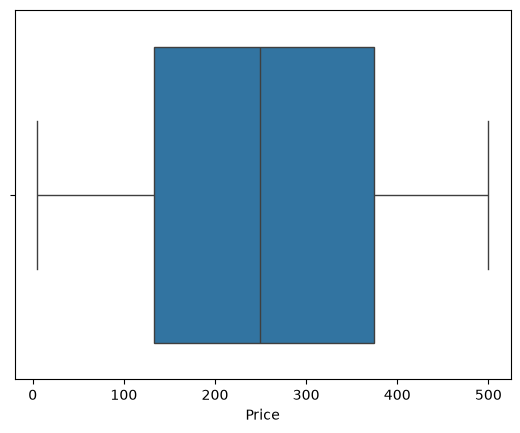

In [12]:
#* Visualicemos los datos 
sns.boxplot(data=df, x='Price')

<Axes: xlabel='CustomerFeedback', ylabel='Count'>

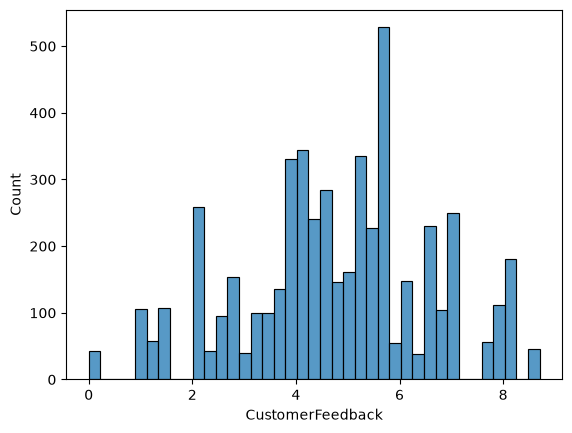

In [13]:
sns.histplot(data=df, x='CustomerFeedback')

In [14]:
#* Variable categoricas
df.describe(include='object')

,TransactionID,CustomerID,TransactionDate,ProductID,ProductCategory,Quantity,PaymentMethod,ReturnStatus
count,5050,4802,5050,4959,5050,4432,3720,5050
unique,5000,501,4999,101,6,7,3,2
top,TXN102515,CUST1276,2023-10-27 02:00:59,PROD287,Electronics,two,Credit Card,No
freq,2,20,2,67,877,685,1301,2560


In [15]:
columns_to_explore = ['ProductCategory', 'Quantity','PaymentMethod','ReturnStatus']
for column in columns_to_explore:
    print(column, ':', df[column].unique(),'\n')

ProductCategory : ['books' 'Home Goods' 'Electronics' 'Books' 'Clothing' 'Accessories'] 

Quantity : [nan '10' '3' 'two' '1' '4' '5' '2'] 

PaymentMethod : ['Credit Card' 'Bank Transfer' nan 'PayPal'] 

ReturnStatus : ['Yes' 'No'] 



Coclusiones:
- ProductCategory tiene categorias similares
- Gestionar nulls, strings y "two"
- PaymentMethods nulls


💡 Los tipos de variables más comunes que nos podemos encontrar:
- int64: valores enteros
- float64: valores decimales
- object: tipo de datos flexible que representa strings o tipos de datos mixtos (ej. alfanumérico)
- datetime64[ns]: fechas y horas
- bool: datos binarios (True/False)

¿Qué conclusiones sacas después de este análisis inicial?



***

## 2. Transformaciones y ajustes de variables
### 2.1 Gestión de nulos y campos vacíos
Lo primero a gestionar son los nulos, ya que tenerlos en nuestros datos nos impedirá hacer otras transformaciones.

In [16]:
# ¿Cuántos nulls hay por cada columna? ¿qué porcentaje del total representan?
df.isnull().sum()


TransactionID          0
CustomerID           248
TransactionDate        0
ProductID             91
ProductCategory        0
Quantity             618
Price                 55
PaymentMethod       1330
ReturnStatus           0
CustomerFeedback       0
DiscountApplied      550
ShippingCost         255
dtype: int64

In [17]:
num_nulls = df.isnull().sum()
percent_nulls = (num_nulls/len(df))*100

print(f'{percent_nulls.round(2)}')

TransactionID        0.00
CustomerID           4.91
TransactionDate      0.00
ProductID            1.80
ProductCategory      0.00
Quantity            12.24
Price                1.09
PaymentMethod       26.34
ReturnStatus         0.00
CustomerFeedback     0.00
DiscountApplied     10.89
ShippingCost         5.05
dtype: float64


In [18]:
df_no_nulls = df.copy()

In [19]:
# ¿Qué estrategias se pueden seguir para gestionar los nulls?
# Implementa la que consideres apropiada para cada variable con nulls

In [20]:
#*CustomerID
df_no_nulls['CustomerID'] = df_no_nulls['CustomerID'].fillna('Unknown')

In [21]:
#*PaymentMethod
display(df_no_nulls['PaymentMethod'].unique())
payment_method_mode = df_no_nulls['PaymentMethod'].mode()[0]
df_no_nulls['PaymentMethod'] = df_no_nulls['PaymentMethod'].fillna(payment_method_mode)

array(['Credit Card', 'Bank Transfer', nan, 'PayPal'], dtype=object)

In [22]:
#*Quantity
#Reemplazar 'two'"Lesson I - Python Basics.ipynb"
df_no_nulls['Quantity'] = df_no_nulls['Quantity'].replace('two', 2)

#Convertir a valores numericos
df_no_nulls['Quantity'] = pd.to_numeric(df_no_nulls['Quantity'], errors='coerce')
display(df_no_nulls['Quantity'].unique())

#transformar Nan
df_no_nulls['Quantity'] = df_no_nulls['Quantity'].fillna(2)


array([nan, 10.,  3.,  2.,  1.,  4.,  5.])

In [23]:
#Transformar a enteros en vez de float
df_no_nulls['Quantity'] = df_no_nulls['Quantity'].astype(int)
display(df_no_nulls['Quantity'].unique())

array([ 2, 10,  3,  1,  4,  5])

In [24]:
#*TransactionDate
df_no_nulls['TransactionDate']= pd.to_datetime(df_no_nulls['TransactionDate'])

In [25]:
df_no_nulls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   TransactionID     5050 non-null   object        
 1   CustomerID        5050 non-null   object        
 2   TransactionDate   5050 non-null   datetime64[ns]
 3   ProductID         4959 non-null   object        
 4   ProductCategory   5050 non-null   object        
 5   Quantity          5050 non-null   int32         
 6   Price             4995 non-null   float64       
 7   PaymentMethod     5050 non-null   object        
 8   ReturnStatus      5050 non-null   object        
 9   CustomerFeedback  5050 non-null   float64       
 10  DiscountApplied   4500 non-null   float64       
 11  ShippingCost      4795 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int32(1), object(6)
memory usage: 453.8+ KB


## 2.2 Ajuste de los tipos de variables
Para poder trabajar correctamente con los datos, hace falta transformar las variables al tipo de datos correcto. 

In [26]:
# ¿Qué variables no tienen el tipo de dato correcto?
# Implementa aquí el código para hacer el ajuste

## 2.3 Gestión de outliers
Los outliers pueden afectar en gran medida a nuestros análisis, es por eso por lo que es muy importante detectarlos y gestionarlos.

In [27]:
df_no_outl = df_no_nulls.copy()

<Axes: xlabel='CustomerFeedback'>

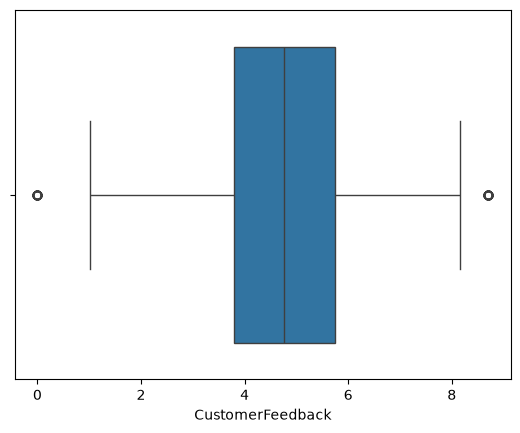

In [28]:
# Analiza las variables numéricas para detectar outliers. 
# ¿Cómo? A través de inspección visual, utilizando métodos estadísticos como el Z Score o el IQR, etc
sns.boxplot(data=df_no_outl, x='CustomerFeedback')

Variables numericas a gestionar: Quantity y CustomerFeedback

In [29]:
#* Gestiona estos outliers
#CustomerFeedback

Q1 = df_no_outl['CustomerFeedback'].quantile(0.25)
Q3 = df_no_outl['CustomerFeedback'].quantile(0.75)
IQR = Q3 - Q1

outl_CF = df_no_outl[(df_no_outl['CustomerFeedback'] < (Q1-1.5*IQR)) | (df_no_outl['CustomerFeedback'] > (Q3+1.5*IQR))]
outl_CF['CustomerFeedback'].value_counts()

CustomerFeedback
8.704556    45
0.000000    42
Name: count, dtype: int64

In [30]:
df_no_outl['CustomerFeedback'] = df_no_outl['CustomerFeedback'].replace(0., df_no_outl['CustomerFeedback'].mean())


En variables categóricas, así como la variable del tiempo, quizá no podemos hablar de outliers propiamente pero vamos a anlizarlas a ver si hay algún caso raro que debamos gestionar.

In [31]:
# Analiza los valores únicos de las variables categóricas y gestiona los casos raros

columns_to_explore = ['ProductCategory','PaymentMethod','ReturnStatus']
for column in columns_to_explore:
    print(column, ':', df[column].unique(),'\n')

ProductCategory : ['books' 'Home Goods' 'Electronics' 'Books' 'Clothing' 'Accessories'] 

PaymentMethod : ['Credit Card' 'Bank Transfer' nan 'PayPal'] 

ReturnStatus : ['Yes' 'No'] 



In [32]:
df_no_outl['ProductCategory'] = df_no_outl['ProductCategory'].replace('books', 'Books')

In [33]:
# Analiza el rango de fechas del dataset y, si es necesario, gestiona los casos raros
display(df_no_outl['TransactionDate'].max())
display(df_no_outl['TransactionDate'].min())

Timestamp('2023-12-31 23:50:44')

Timestamp('2023-01-01 00:19:58')

## 2.4 Gestión de duplicados

In [34]:
df_no_dupl = df_no_outl.copy()

In [35]:
# Analiza si hay duplicados en el dataset, en general o por un subset de las columnas
df_no_dupl.duplicated().sum()

df_no_dupl[df_no_dupl.duplicated()]

,TransactionID,CustomerID,TransactionDate,ProductID,ProductCategory,Quantity,Price,PaymentMethod,ReturnStatus,CustomerFeedback,DiscountApplied,ShippingCost
5000,TXN101501,CUST1461,2023-09-21 20:53:19,PROD266,Books,10,312.26,PayPal,Yes,4.229835,15.92,11.02
5001,TXN102586,CUST1236,2023-11-16 12:54:38,PROD275,Home Goods,4,397.64,Credit Card,Yes,3.875425,14.08,18.90
5002,TXN102653,CUST1331,2023-11-06 11:11:13,PROD213,Home Goods,4,361.77,Credit Card,No,4.530826,36.46,14.26
5003,TXN101055,CUST1449,2023-07-23 21:00:01,PROD247,Books,4,320.63,Credit Card,No,4.061051,49.64,28.87
5004,TXN100705,CUST1443,2023-08-21 23:10:01,PROD210,Clothing,5,181.68,Bank Transfer,No,5.393722,29.42,36.73
5005,TXN100106,CUST1117,2023-02-19 02:40:44,PROD229,Electronics,2,317.74,Credit Card,No,2.787330,33.63,12.08
5006,TXN100589,CUST1326,2023-01-14 09:02:57,PROD222,Accessories,4,238.09,Credit Card,No,5.483925,41.37,32.37
5007,TXN102468,CUST1284,2023-07-10 11:57:45,PROD208,Home Goods,2,313.09,PayPal,No,4.772651,NaN,20.99
5008,TXN102413,CUST1153,2023-03-10 15:17:30,PROD264,Clothing,4,212.17,Credit Card,No,6.625052,32.62,49.18
5009,TXN101600,CUST1095,2023-11-12 10:13:04,PROD242,Accessories,3,200.56,Credit Card,Yes,5.751396,38.02,22.98


In [36]:
df_no_dupl.drop_duplicates(inplace=True)

***

## 3. Feature Engineering: creación de nuevas variables
En algunos casos, podemos crear nuevas variables a partir de las que ya tenemos, que puedan enriquecer el análisis.

In [37]:
df_cleaned = df_no_dupl.copy()

In [38]:
mapping = {'No': 0, 'Yes':1}
df_cleaned['ReturnStatusBool'] = df_cleaned['ReturnStatus'].map(mapping)

In [39]:
df_cleaned['TotalAmount'] = df_cleaned['Price'] * df_cleaned['Quantity']


In [40]:
#Categorias de feedback

feedback_categories = ['Very Bad', 'Bad', 'OK', 'Good', 'Very Good']
range = [0, 3, 5, 7, 9, 10.01]

df_cleaned['CustomerFeedbackGroup'] = pd.cut(df_cleaned['CustomerFeedback'], bins = range, labels= feedback_categories)

In [41]:
df_cleaned[['CustomerFeedback', 'CustomerFeedbackGroup']].head()

,CustomerFeedback,CustomerFeedbackGroup
0,4.344676,Bad
1,6.534869,OK
2,8.076073,Good
3,4.855980,Bad
4,2.042956,Very Bad


In [42]:
# ¿Qué variables podría ser interesante crear?
# Algunas ideas con pistas, enfocadas en el análisis que queremos hacer:
# - Nos piden hacer un análisis de la facturación total por meses
# - Nos piden segmentar los productos y categorías de productos por el feedback recibido, para saber los que peor valoración tienen

***

## 4. Combinación con otros datasets
Además del dataset de transacciones, contamos con un dataset sobre los clientes, que podremos utilizar para hacer análisis más completos.

In [43]:
# Carga el dataset
df_customers = pd.read_csv(r"C:\Users\Adrian\Desktop\CODE_SPACE\Ejercicios\Python_Basics_for_DS\data\ecommerce\ecommerce_customers.csv")
df_customers.head()

,CustomerID,Location,Age,Gender,CustomerSince,LoyaltyPoints
0,CUST1012,Los Angeles,46,Female,2022-09-02,3828
1,CUST1125,NY,60,Other,2023-11-28,1008
2,CUST1377,LA,28,Male,2022-09-29,1229
3,CUST1379,Phoenix,35,Female,2023-03-16,1035
4,CUST1044,Los Angeles,64,Male,2022-08-27,4585


In [47]:
# Haz un análisis general del dataset para entender qué columnas tiene
df_customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 501 entries, 0 to 500
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerID     501 non-null    object
 1   Location       501 non-null    object
 2   Age            501 non-null    int64 
 3   Gender         501 non-null    object
 4   CustomerSince  501 non-null    object
 5   LoyaltyPoints  501 non-null    int64 
dtypes: int64(2), object(4)
memory usage: 23.6+ KB


In [56]:
# ¿Hace falta gestionar algún null, tipo de variable, outlier o duplicado como hemos hecho previamente?

#*Cambiamos tipo de variable de CustomerSince
df_customers['CustomerSince'] = pd.to_datetime(df_customers['CustomerSince'], format= '%Y-%m-%d')
display(df_customers.dtypes)
display(df_customers.head())


CustomerID               object
Location                 object
Age                       int64
Gender                   object
CustomerSince    datetime64[ns]
LoyaltyPoints             int64
dtype: object

,CustomerID,Location,Age,Gender,CustomerSince,LoyaltyPoints
0,CUST1012,Los Angeles,46,Female,2022-09-02,3828
1,CUST1125,NY,60,Other,2023-11-28,1008
2,CUST1377,LA,28,Male,2022-09-29,1229
3,CUST1379,Phoenix,35,Female,2023-03-16,1035
4,CUST1044,Los Angeles,64,Male,2022-08-27,4585


<Axes: xlabel='Age', ylabel='Count'>

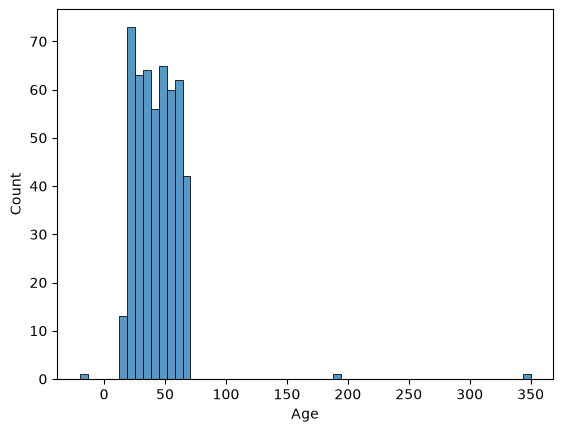

In [64]:
#Distribuciones y outliers

sns.histplot(data=df_customers, x='Age')

<Axes: xlabel='LoyaltyPoints', ylabel='Count'>

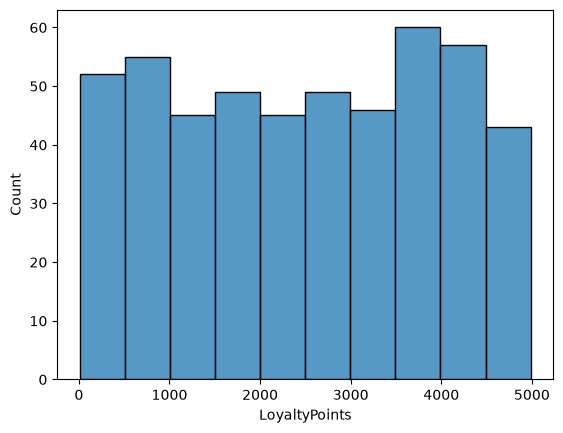

In [59]:
#Distribuciones y outliers

sns.histplot(data=df_customers, x='LoyaltyPoints')

In [65]:
#Gestinamos los outliers de Age (implementamos ahora el metodo Z-score desde scipy)
from scipy.stats import zscore

print('Media: ', df_customers['Age'].mean())
print('STD: ', df_customers['Age'].std())
print(df_customers['Age'].head())
df_customers['Age_zscore']=zscore(df_customers['Age'])
df_customers.head()


Media:  43.395209580838326
STD:  21.62867302924495
0    46
1    60
2    28
3    35
4    64
Name: Age, dtype: int64


,CustomerID,Location,Age,Gender,CustomerSince,LoyaltyPoints,Age_zscore
0,CUST1012,Los Angeles,46,Female,2022-09-02,3828,0.120553
1,CUST1125,NY,60,Other,2023-11-28,1008,0.768489
2,CUST1377,LA,28,Male,2022-09-29,1229,-0.712508
3,CUST1379,Phoenix,35,Female,2023-03-16,1035,-0.388540
4,CUST1044,Los Angeles,64,Male,2022-08-27,4585,0.953613


In [67]:
age_outliers = df_customers[abs(df_customers['Age_zscore'])>3]
age_outliers

,CustomerID,Location,Age,Gender,CustomerSince,LoyaltyPoints,Age_zscore
55,CUST1440,New York,350,Male,2023-06-01,3828,14.190017
405,CUST1021,Phoenix,190,Female,2023-07-16,593,6.785036


In [68]:
df_customers.loc[age_outliers.index,'Age'] = df_customers['Age'].median()

<Axes: xlabel='Age'>

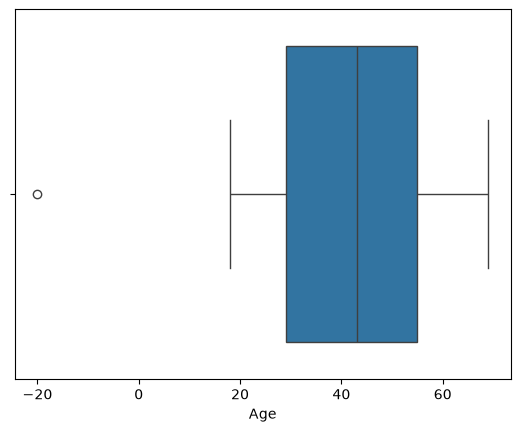

In [69]:
sns.boxplot(data=df_customers, x='Age')

In [70]:
#Todavia queda un outlier pendiente que el Zscore no ha sabido resolver. Hacemos un replace directamente. (Yo creo que usar el Zscore para la edad es terrible)
df_customers['Age']= df_customers['Age'].replace(-20, df_customers['Age'].median())

In [72]:
df_cust_cleaned = df_customers.copy()

In [73]:
# Gestionamos los diferentes valores que hay en location

df_cust_cleaned['Location'].unique()

array(['Los Angeles', 'NY', 'LA', 'Phoenix', 'Houston', 'New York',
       'Chicago'], dtype=object)

In [74]:
df_cust_cleaned['Location'] = df_cust_cleaned['Location'].replace({'NY':'New York', 'LA':'Los Angeles'})
df_cust_cleaned['Location'].unique()

array(['Los Angeles', 'New York', 'Phoenix', 'Houston', 'Chicago'],
      dtype=object)

In [75]:
#Hay duplicados?
df_cust_cleaned.duplicated().sum()

0

Una vez hemos entendido y limpiado (en caso de ser necesario) el dataset sobre clientes, nos proponemos contestar las siguientes preguntas: <n>

¿Dónde vendemos más productos? ¿Y qué categoría de productos? ¿Quiénes son nuestros clientes?

In [76]:
# Guía para hacer joins en pandas: https://pandas.pydata.org/pandas-docs/stable/user_guide/merging.html#merging-join

# ¿Qué tipo de join es más apropiado en este caso? 
display(df_cleaned)
display(df_cust_cleaned)

,TransactionID,CustomerID,TransactionDate,ProductID,ProductCategory,Quantity,Price,PaymentMethod,ReturnStatus,CustomerFeedback,DiscountApplied,ShippingCost,ReturnStatusBool,TotalAmount,CustomerFeedbackGroup
0,TXN100000,CUST1012,2023-06-05 11:11:00,PROD215,Books,2,238.10,Credit Card,Yes,4.344676,15.04,47.16,1,476.20,Bad
1,TXN100001,CUST1125,2023-03-13 13:16:59,PROD300,Home Goods,10,480.70,Bank Transfer,Yes,6.534869,13.70,30.15,1,4807.00,OK
2,TXN100002,CUST1377,2023-11-17 19:39:50,PROD230,Electronics,3,361.89,Credit Card,No,8.076073,19.09,15.58,0,1085.67,Good
3,TXN100003,CUST1379,2023-01-03 14:41:06,PROD283,Books,2,9.69,Credit Card,Yes,4.855980,31.34,35.70,1,19.38,Bad
4,TXN100004,CUST1044,2023-05-21 21:42:03,PROD214,Home Goods,2,351.01,Credit Card,No,2.042956,39.82,4.04,0,702.02,Very Bad
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,TXN104995,CUST1319,2023-11-23 18:39:09,NaN,Home Goods,1,150.03,PayPal,Yes,7.712480,10.14,4.62,1,150.03,Good
4996,TXN104996,CUST1246,2023-07-22 08:01:29,PROD221,Electronics,4,347.67,Bank Transfer,Yes,5.135056,8.84,27.35,1,1390.68,OK
4997,TXN104997,CUST1487,2023-03-31 12:45:02,NaN,Books,5,214.65,Bank Transfer,No,5.393722,NaN,9.61,0,1073.25,OK
4998,TXN104998,CUST1413,2023-04-29 10:14:21,PROD287,Books,1,68.61,Bank Transfer,No,4.560656,33.03,43.71,0,68.61,Bad


,CustomerID,Location,Age,Gender,CustomerSince,LoyaltyPoints,Age_zscore
0,CUST1012,Los Angeles,46,Female,2022-09-02,3828,0.120553
1,CUST1125,New York,60,Other,2023-11-28,1008,0.768489
2,CUST1377,Los Angeles,28,Male,2022-09-29,1229,-0.712508
3,CUST1379,Phoenix,35,Female,2023-03-16,1035,-0.388540
4,CUST1044,Los Angeles,64,Male,2022-08-27,4585,0.953613
...,...,...,...,...,...,...,...
496,CUST1438,Phoenix,35,Male,2022-01-01,4878,-0.388540
497,CUST1114,New York,57,Female,2022-04-29,2320,0.629645
498,CUST1106,Chicago,25,Male,2022-02-04,935,-0.851351
499,CUST1499,Los Angeles,56,Male,2022-07-17,2230,0.583364


In [ ]:
# Se quiere unir ambos dataframe para añadir la informacion de los clientes de la segunda tabla solo para los clientes que ya hayan hecho una transaccion,
# olvidandonos de aquellos customers que no hayan hecho ninguna transaccion
df_merged = pd.merge(df_cleaned, df_cust_cleaned, on= 'CustomerID', how='left')
df_merged.head()

,TransactionID,CustomerID,TransactionDate,ProductID,ProductCategory,Quantity,Price,PaymentMethod,ReturnStatus,CustomerFeedback,...,ShippingCost,ReturnStatusBool,TotalAmount,CustomerFeedbackGroup,Location,Age,Gender,CustomerSince,LoyaltyPoints,Age_zscore
0,TXN100000,CUST1012,2023-06-05 11:11:00,PROD215,Books,2,238.10,Credit Card,Yes,4.344676,...,47.16,1,476.20,Bad,Los Angeles,46.0,Female,2022-09-02,3828.0,0.120553
1,TXN100001,CUST1125,2023-03-13 13:16:59,PROD300,Home Goods,10,480.70,Bank Transfer,Yes,6.534869,...,30.15,1,4807.00,OK,New York,60.0,Other,2023-11-28,1008.0,0.768489
2,TXN100002,CUST1377,2023-11-17 19:39:50,PROD230,Electronics,3,361.89,Credit Card,No,8.076073,...,15.58,0,1085.67,Good,Los Angeles,28.0,Male,2022-09-29,1229.0,-0.712508
3,TXN100003,CUST1379,2023-01-03 14:41:06,PROD283,Books,2,9.69,Credit Card,Yes,4.855980,...,35.70,1,19.38,Bad,Phoenix,35.0,Female,2023-03-16,1035.0,-0.388540
4,TXN100004,CUST1044,2023-05-21 21:42:03,PROD214,Home Goods,2,351.01,Credit Card,No,2.042956,...,4.04,0,702.02,Very Bad,Los Angeles,64.0,Male,2022-08-27,4585.0,0.953613


***

In [81]:
# Conteo de pedidos por localizacion
transactions_by_location = df_merged.groupby('Location').size().reset_index(name='TransactionCount')
transactions_by_location

,Location,TransactionCount
0,Chicago,665
1,Houston,656
2,Los Angeles,1394
3,New York,1453
4,Phoenix,585


<Axes: xlabel='Location', ylabel='TransactionCount'>

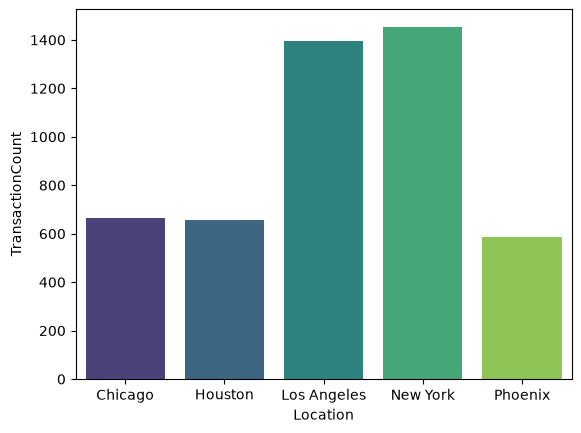

In [83]:
sns.barplot(data=transactions_by_location, x='Location', y= 'TransactionCount', hue='Location', palette='viridis')

## 5. Análisis de negocio
Una vez hemos limpiado y preparado nuestros datasets, podemos hacer un análisis más enfocado a negocio. ¿Qué ocurrirá? Que a medida que vayamos planteando preguntas, tendremos que hacer ajustes similares a los que ya hemos hecho, generando nuevas variables y ajustando los datos al objetivo concreto.

### Entender el comportamiento de compra

#### Analizar la frecuencia de compra, el tamaño de la compra media y los productos mas populares


In [87]:
#Cuantas transacciones hace cada cliente?
purchase_freq = df_merged.groupby('CustomerID')['TransactionID'].size().reset_index(name='PurchaseFreq')

purchase_freq.sort_values(by='PurchaseFreq', ascending = False).head(6)

,CustomerID,PurchaseFreq
501,Unknown,247
205,CUST1205,19
276,CUST1276,19
360,CUST1360,19
243,CUST1243,18
255,CUST1255,18


In [90]:
top5_clients = ["CUST1205", "CUST1276", "CUST1360", "CUST1243", "CUST1255"]

for cust in top5_clients:
    print('Client: ', cust)
    display(df_cust_cleaned[df_cust_cleaned['CustomerID']== cust])

Client:  CUST1205


,CustomerID,Location,Age,Gender,CustomerSince,LoyaltyPoints,Age_zscore
42,CUST1205,Los Angeles,44,Female,2023-08-07,4909,0.02799


Client:  CUST1276


,CustomerID,Location,Age,Gender,CustomerSince,LoyaltyPoints,Age_zscore
74,CUST1276,New York,28,Female,2022-11-25,2772,-0.712508


Client:  CUST1360


,CustomerID,Location,Age,Gender,CustomerSince,LoyaltyPoints,Age_zscore
24,CUST1360,New York,36,Other,2023-02-03,128,-0.342259


Client:  CUST1243


,CustomerID,Location,Age,Gender,CustomerSince,LoyaltyPoints,Age_zscore
84,CUST1243,Phoenix,31,Female,2022-07-14,4400,-0.573664


Client:  CUST1255


,CustomerID,Location,Age,Gender,CustomerSince,LoyaltyPoints,Age_zscore
46,CUST1255,Houston,56,Male,2022-08-31,2408,0.583364


In [95]:
# Cuanto se gastan de media nuestros clientes?
avg_purch_by_location = df_merged.groupby(['CustomerID', 'Location'])['TotalAmount'].mean().reset_index(name='AvgPurchase')
avg_purch_by_location

,CustomerID,Location,AvgPurchase
0,CUST1000,New York,1062.548750
1,CUST1001,New York,714.080000
2,CUST1002,Chicago,934.763750
3,CUST1003,New York,349.690000
4,CUST1004,New York,977.911818
...,...,...,...
496,CUST1496,Houston,1319.240000
497,CUST1497,Los Angeles,699.002857
498,CUST1498,Chicago,1594.580000
499,CUST1499,Los Angeles,858.420000


<Axes: xlabel='AvgPurchase'>

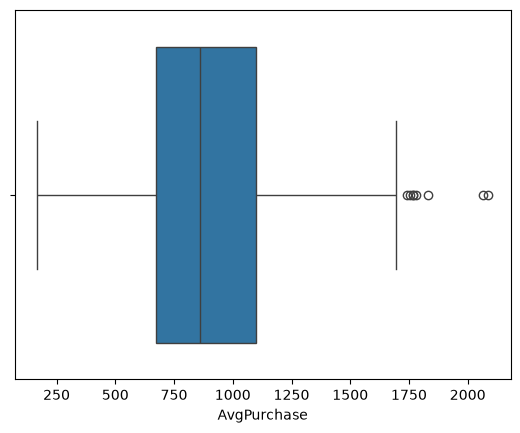

In [96]:
sns.boxplot(data=avg_purch_by_location, x='AvgPurchase')